# ✈️ PRCP-1025: Flight Fare Prediction
**Internship Project | Data Science & Machine Learning**

---
| Task | Description |
|------|-------------|
| Task 1 | Complete Exploratory Data Analysis (EDA) Report |
| Task 2 | Build Predictive Models for Flight Fare |
| Task 3 | Model Comparison Report |
| Task 4 | Challenges Faced & Techniques Used |

**Dataset:** Flight Fare Dataset — 11 attributes, ~10,683 records  
**Target Variable:** `Price` (flight fare in INR)

## Step 1: Import Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
print('All libraries imported successfully!')

All libraries imported successfully!


## Step 2: Load Dataset

In [6]:
# Step 1: Upload the zip file
from google.colab import files
uploaded = files.upload()  # File picker will open → select your zip

# Step 2: Extract the zip
import zipfile
import os

zip_name = list(uploaded.keys())[0]  # gets the zip filename automatically
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('flight_data')       # extracts to folder named 'flight_data'
    print('Files extracted:', z.namelist())

# Step 3: Find and load the CSV
import pandas as pd

for root, dirs, files_list in os.walk('flight_data'):
    for file in files_list:
        if file.endswith('.csv') or file.endswith('.xlsx'):
            filepath = os.path.join(root, file)
            print(f'Found: {filepath}')
            if file.endswith('.csv'):
                df = pd.read_csv(filepath)
            else:
                df = pd.read_excel(filepath)
            print(f'Loaded! Shape: {df.shape}')
            break

df.head()

Saving flight-fare.zip to flight-fare.zip
Files extracted: ['Flight_Fare.xlsx']
Found: flight_data/Flight_Fare.xlsx
Loaded! Shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


---
# TASK 1: Data Analysis Report

###  Dataset Overview

In [7]:
print('SHAPE:', df.shape)
print('\nCOLUMNS:', df.columns.tolist())
print('\nDATA TYPES:')
print(df.dtypes)
print('\nDUPLICATES:', df.duplicated().sum())

SHAPE: (10683, 11)

COLUMNS: ['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price']

DATA TYPES:
Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

DUPLICATES: 220


###  Statistical Summary

In [8]:
print('=== NUMERICAL SUMMARY ===')
display(df.describe())
print('\n=== CATEGORICAL SUMMARY ===')
display(df.describe(include='object'))

=== NUMERICAL SUMMARY ===


,Price
count,10683.00
mean,9087.06
std,4611.36
min,1759.00
25%,5277.00
50%,8372.00
75%,12373.00
max,79512.00



=== CATEGORICAL SUMMARY ===


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


###  Missing Value Analysis

MISSING VALUES:
             Missing Count  Missing %
Route                    1       0.01
Total_Stops              1       0.01


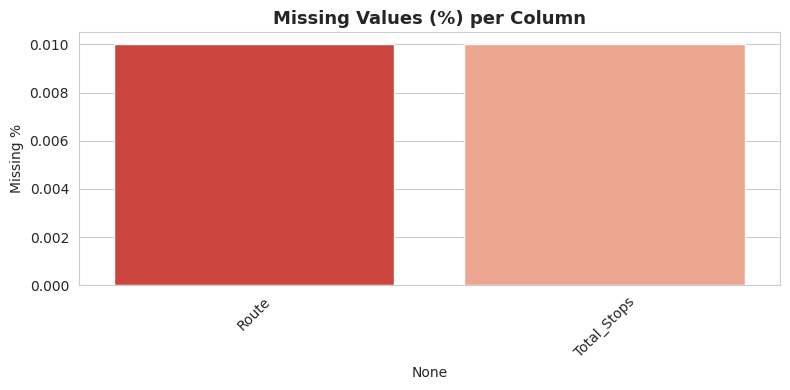

In [9]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct.round(2)})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_df) > 0:
    print('MISSING VALUES:')
    print(missing_df)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_df.index, y=missing_df['Missing %'], palette='Reds_r')
    plt.title('Missing Values (%) per Column', fontsize=13, fontweight='bold')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('No missing values found in dataset!')

### Target Variable (Price) Distribution

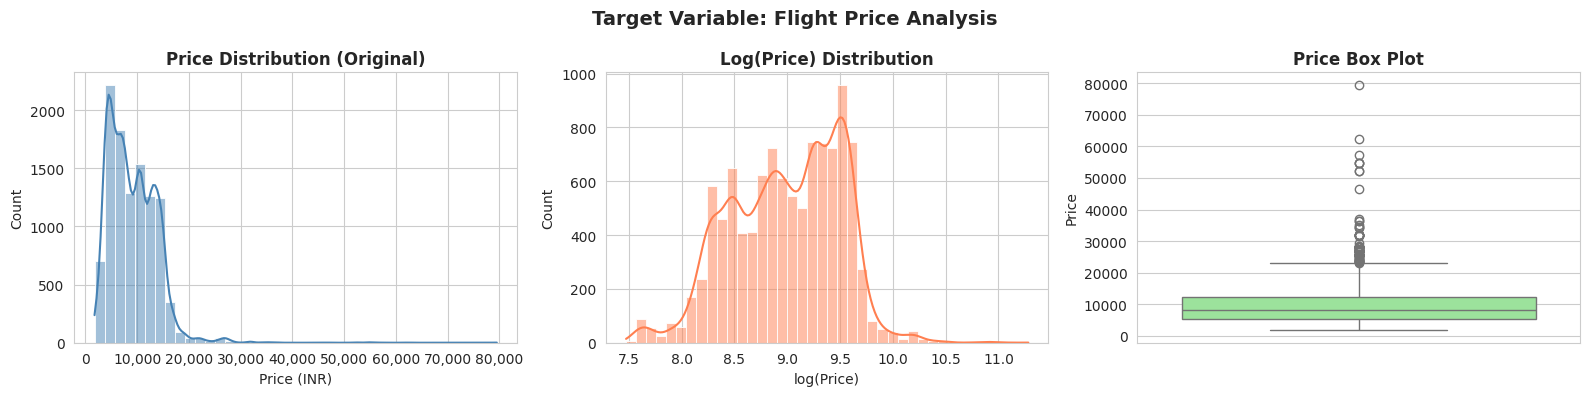

Mean   : INR      9,087
Median : INR      8,372
Std Dev: INR      4,611
Min    : INR      1,759
Max    : INR     79,512
Skewness: 1.813


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['Price'].dropna(), kde=True, bins=40, color='steelblue', ax=axes[0])
axes[0].set_title('Price Distribution (Original)', fontweight='bold')
axes[0].set_xlabel('Price (INR)')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

sns.histplot(np.log1p(df['Price'].dropna()), kde=True, bins=40, color='coral', ax=axes[1])
axes[1].set_title('Log(Price) Distribution', fontweight='bold')
axes[1].set_xlabel('log(Price)')

sns.boxplot(y=df['Price'], color='lightgreen', ax=axes[2])
axes[2].set_title('Price Box Plot', fontweight='bold')

plt.suptitle('Target Variable: Flight Price Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Mean   : INR {df['Price'].mean():>10,.0f}")
print(f"Median : INR {df['Price'].median():>10,.0f}")
print(f"Std Dev: INR {df['Price'].std():>10,.0f}")
print(f"Min    : INR {df['Price'].min():>10,.0f}")
print(f"Max    : INR {df['Price'].max():>10,.0f}")
print(f"Skewness: {df['Price'].skew():.3f}")

###  Airline Analysis

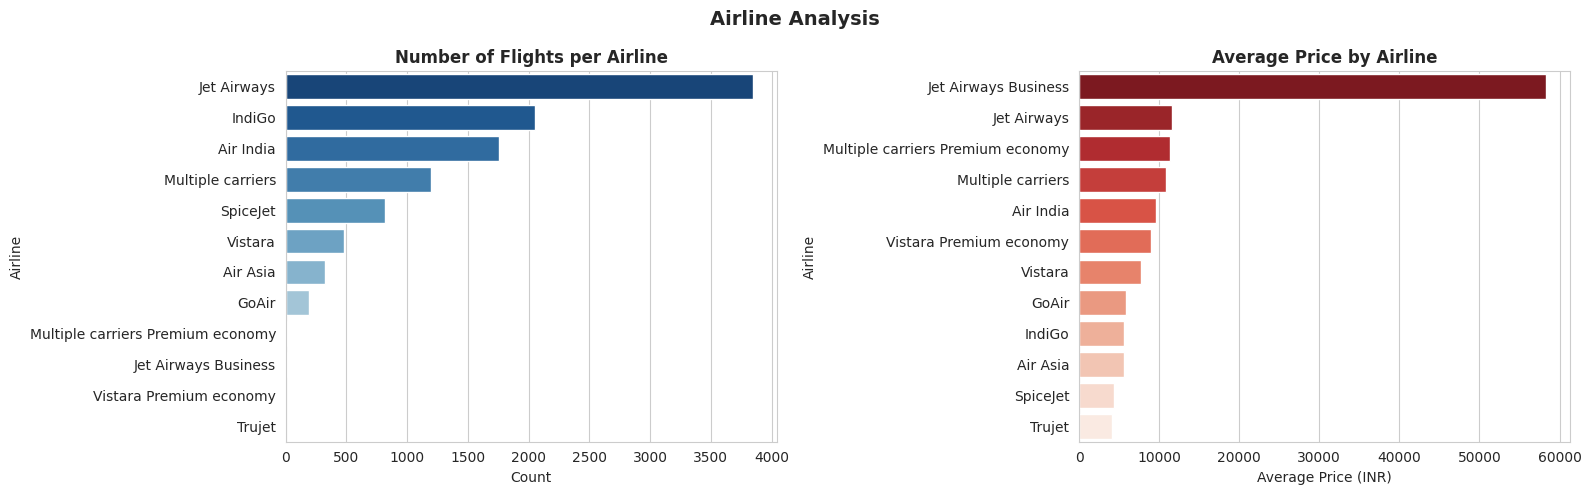

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Count of flights per airline
airline_count = df['Airline'].value_counts()
sns.barplot(x=airline_count.values, y=airline_count.index, palette='Blues_r', ax=axes[0])
axes[0].set_title('Number of Flights per Airline', fontweight='bold')
axes[0].set_xlabel('Count')

# Average price per airline
airline_price = df.groupby('Airline')['Price'].mean().sort_values(ascending=False)
colors = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(airline_price))]
sns.barplot(x=airline_price.values, y=airline_price.index, palette='Reds_r', ax=axes[1])
axes[1].set_title('Average Price by Airline', fontweight='bold')
axes[1].set_xlabel('Average Price (INR)')

plt.suptitle('Airline Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Source & Destination Analysis

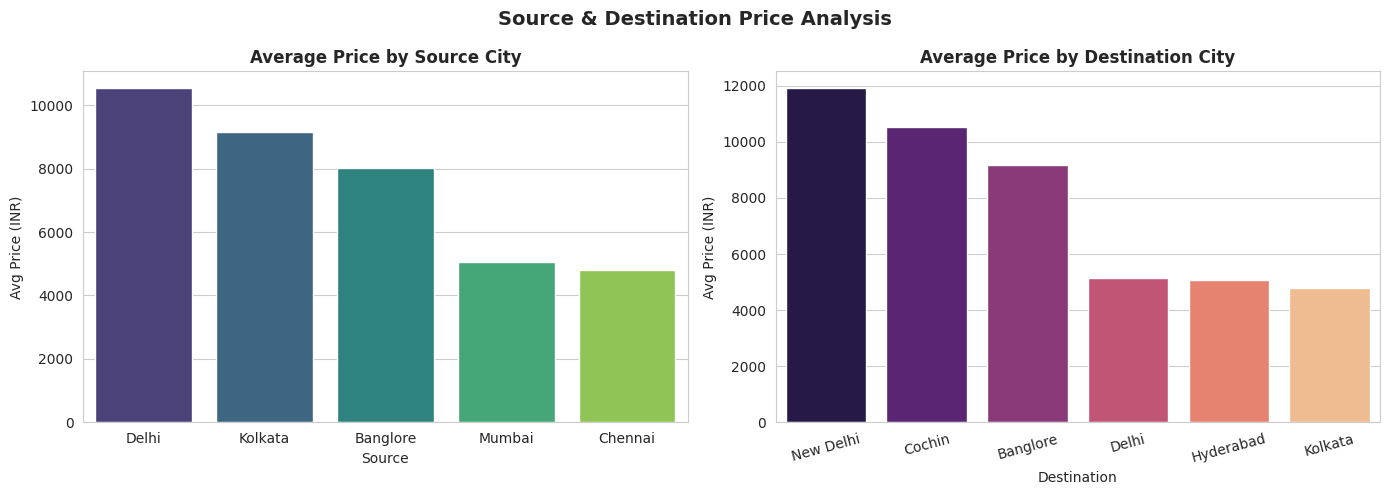

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

src_price = df.groupby('Source')['Price'].mean().sort_values(ascending=False)
sns.barplot(x=src_price.index, y=src_price.values, palette='viridis', ax=axes[0])
axes[0].set_title('Average Price by Source City', fontweight='bold')
axes[0].set_ylabel('Avg Price (INR)')

dst_price = df.groupby('Destination')['Price'].mean().sort_values(ascending=False)
sns.barplot(x=dst_price.index, y=dst_price.values, palette='magma', ax=axes[1])
axes[1].set_title('Average Price by Destination City', fontweight='bold')
axes[1].set_ylabel('Avg Price (INR)')
axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Source & Destination Price Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

###  Stops vs Price

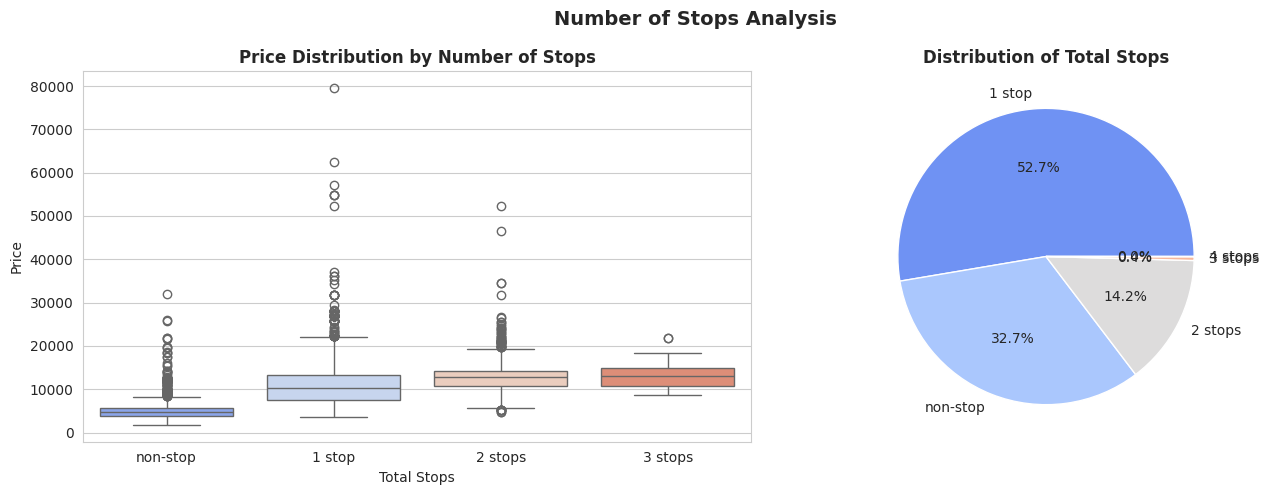

Average price by stops:
Total_Stops
4 stops    17686.00
3 stops    13112.00
2 stops    12715.81
1 stop     10594.12
non-stop    5024.90
Name: Price, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stop_order = ['non-stop', '1 stop', '2 stops', '3 stops']
stop_order = [s for s in stop_order if s in df['Total_Stops'].unique()]

sns.boxplot(data=df, x='Total_Stops', y='Price', order=stop_order,
            palette='coolwarm', ax=axes[0])
axes[0].set_title('Price Distribution by Number of Stops', fontweight='bold')
axes[0].set_xlabel('Total Stops')

stop_count = df['Total_Stops'].value_counts()
axes[1].pie(stop_count.values, labels=stop_count.index,
            autopct='%1.1f%%', colors=sns.color_palette('coolwarm', len(stop_count)))
axes[1].set_title('Distribution of Total Stops', fontweight='bold')

plt.suptitle('Number of Stops Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Average price by stops:')
print(df.groupby('Total_Stops')['Price'].mean().sort_values(ascending=False))

### Journey Month & Day Analysis

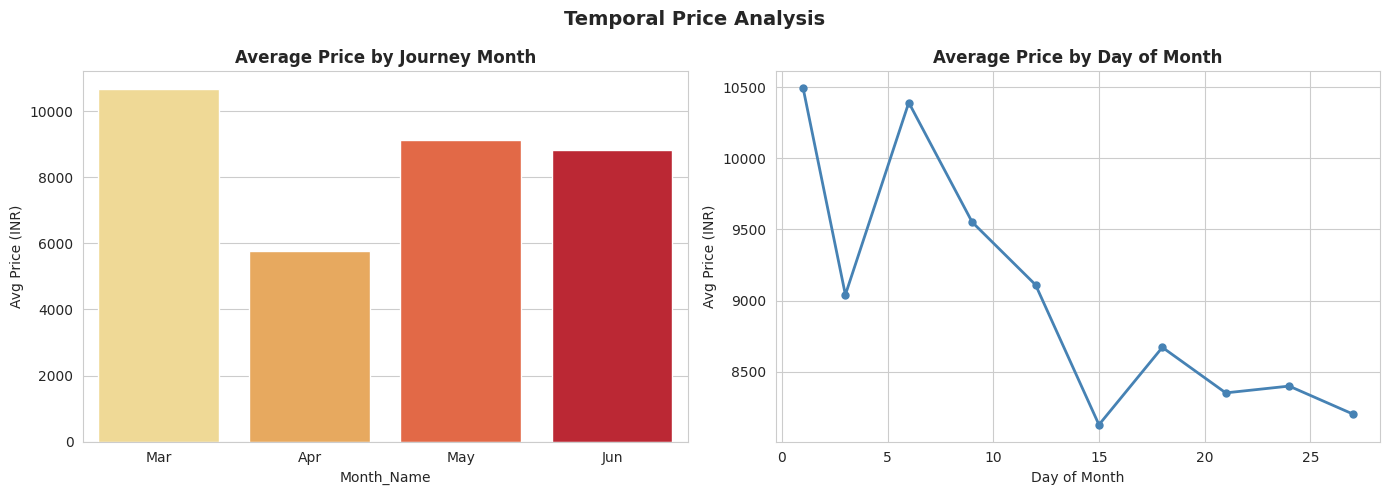

In [14]:
# Extract month and day from Date_of_Journey
df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'], dayfirst=True, errors='coerce')
df['Journey_Month'] = df['Date_of_Journey'].dt.month
df['Journey_Day'] = df['Date_of_Journey'].dt.day

month_names = {3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec', 1:'Jan', 2:'Feb'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

month_price = df.groupby('Journey_Month')['Price'].mean().reset_index()
month_price['Month_Name'] = month_price['Journey_Month'].map(month_names)
sns.barplot(data=month_price, x='Month_Name', y='Price', palette='YlOrRd', ax=axes[0])
axes[0].set_title('Average Price by Journey Month', fontweight='bold')
axes[0].set_ylabel('Avg Price (INR)')

day_price = df.groupby('Journey_Day')['Price'].mean().reset_index()
axes[1].plot(day_price['Journey_Day'], day_price['Price'], marker='o',
             color='steelblue', linewidth=2, markersize=5)
axes[1].set_title('Average Price by Day of Month', fontweight='bold')
axes[1].set_xlabel('Day of Month')
axes[1].set_ylabel('Avg Price (INR)')

plt.suptitle('Temporal Price Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Departure Time vs Price

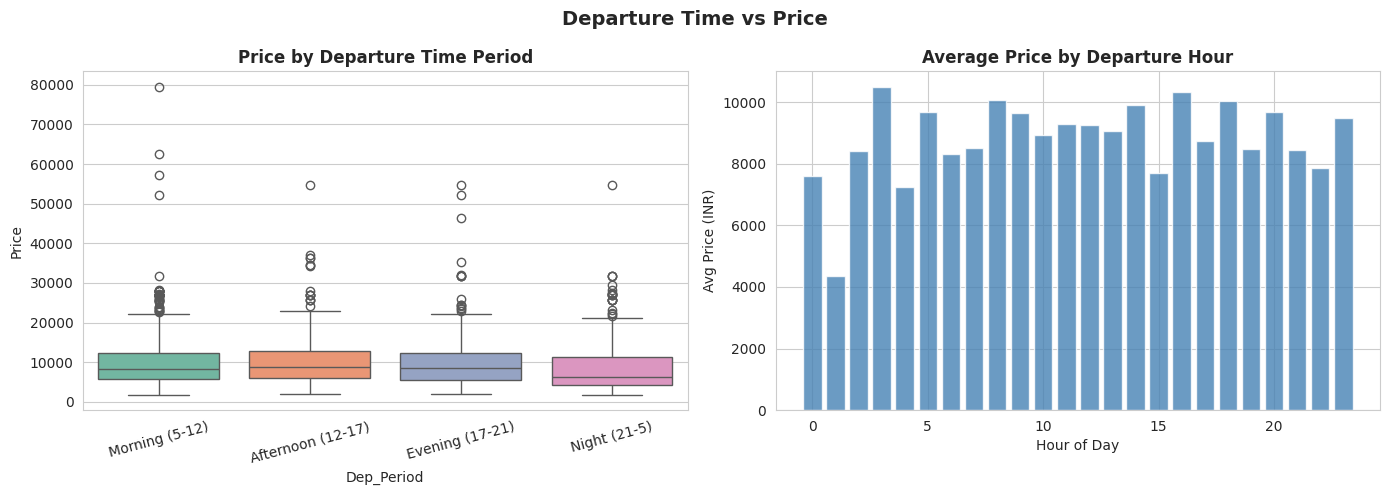

In [15]:
def extract_hour(time_str):
    try:
        return int(str(time_str).split(':')[0])
    except:
        return np.nan

df['Dep_Hour'] = df['Dep_Time'].apply(extract_hour)

def hour_to_period(h):
    if pd.isna(h): return 'Unknown'
    if 5 <= h < 12:  return 'Morning (5-12)'
    if 12 <= h < 17: return 'Afternoon (12-17)'
    if 17 <= h < 21: return 'Evening (17-21)'
    return 'Night (21-5)'

df['Dep_Period'] = df['Dep_Hour'].apply(hour_to_period)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

period_order = ['Morning (5-12)', 'Afternoon (12-17)', 'Evening (17-21)', 'Night (21-5)']
period_order = [p for p in period_order if p in df['Dep_Period'].unique()]
sns.boxplot(data=df, x='Dep_Period', y='Price', order=period_order,
            palette='Set2', ax=axes[0])
axes[0].set_title('Price by Departure Time Period', fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

hour_price = df.groupby('Dep_Hour')['Price'].mean().reset_index()
axes[1].bar(hour_price['Dep_Hour'], hour_price['Price'], color='steelblue', alpha=0.8)
axes[1].set_title('Average Price by Departure Hour', fontweight='bold')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Avg Price (INR)')

plt.suptitle('Departure Time vs Price', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

###  Duration vs Price

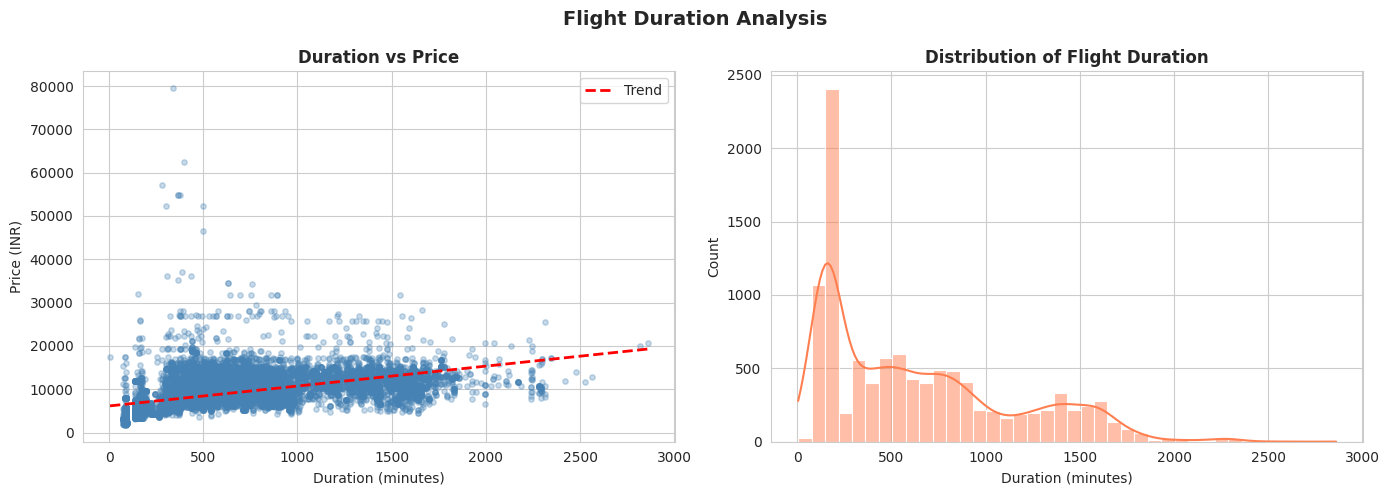

Correlation between Duration and Price: 0.5064


In [16]:
def parse_duration(dur):
    try:
        dur = str(dur)
        parts = dur.replace('h','').replace('m','').split()
        if len(parts) == 2:
            return int(parts[0]) * 60 + int(parts[1])
        elif 'h' in dur:
            return int(parts[0]) * 60
        else:
            return int(parts[0])
    except:
        return np.nan

df['Duration_Mins'] = df['Duration'].apply(parse_duration)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['Duration_Mins'], df['Price'], alpha=0.3, color='steelblue', s=15)
mask = df[['Duration_Mins','Price']].dropna()
z = np.polyfit(mask['Duration_Mins'], mask['Price'], 1)
p = np.poly1d(z)
x_line = np.linspace(mask['Duration_Mins'].min(), mask['Duration_Mins'].max(), 100)
axes[0].plot(x_line, p(x_line), 'r--', lw=2, label='Trend')
axes[0].set_xlabel('Duration (minutes)')
axes[0].set_ylabel('Price (INR)')
axes[0].set_title('Duration vs Price', fontweight='bold')
axes[0].legend()

sns.histplot(df['Duration_Mins'].dropna(), kde=True, bins=40, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Flight Duration', fontweight='bold')
axes[1].set_xlabel('Duration (minutes)')

plt.suptitle('Flight Duration Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

corr = df[['Duration_Mins','Price']].corr().iloc[0,1]
print(f'Correlation between Duration and Price: {corr:.4f}')

###  Airline Price Distribution (Violin Plot)

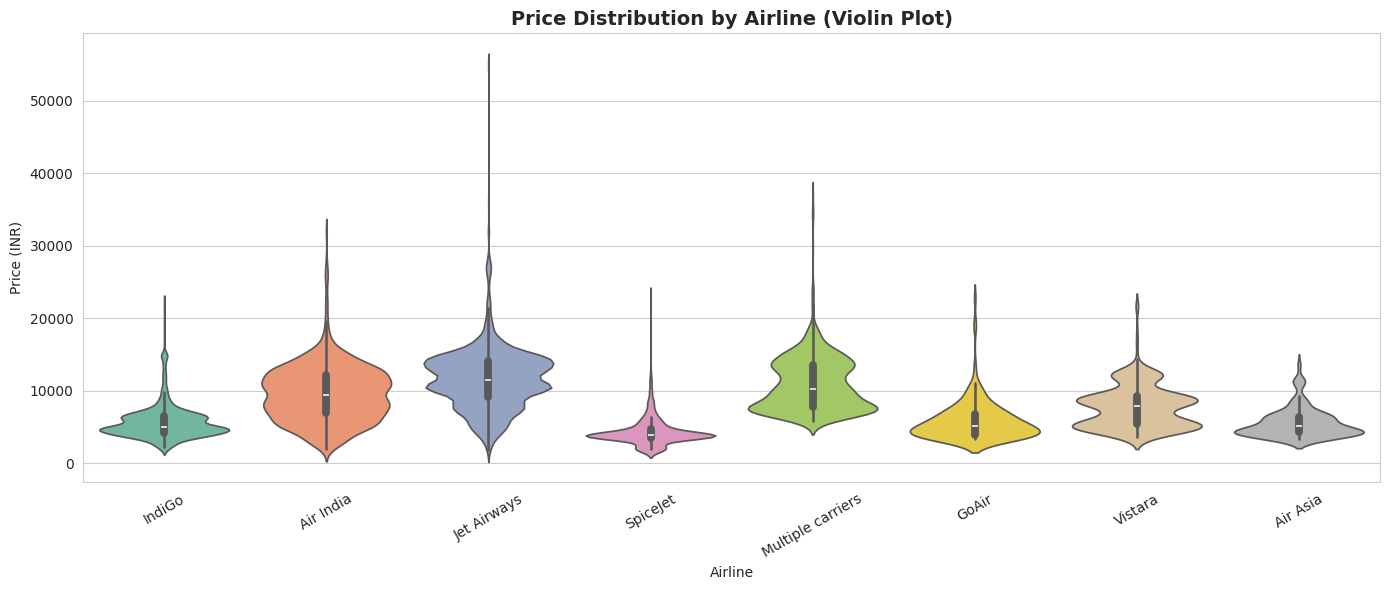

In [17]:
top_airlines = df['Airline'].value_counts().head(8).index.tolist()
df_top = df[df['Airline'].isin(top_airlines)]

plt.figure(figsize=(14, 6))
sns.violinplot(data=df_top, x='Airline', y='Price', palette='Set2', inner='box')
plt.title('Price Distribution by Airline (Violin Plot)', fontsize=14, fontweight='bold')
plt.xticks(rotation=30)
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

---
# Data Preprocessing & Model Building

###  Feature Engineering from Date & Time Columns

In [18]:
df_model = df.copy()

# --- Date features ---
df_model['Date_of_Journey'] = pd.to_datetime(df_model['Date_of_Journey'], dayfirst=True, errors='coerce')
df_model['Journey_Day']   = df_model['Date_of_Journey'].dt.day
df_model['Journey_Month'] = df_model['Date_of_Journey'].dt.month

# --- Departure time ---
df_model['Dep_Hour'] = df_model['Dep_Time'].apply(lambda x: int(str(x).split(':')[0]) if pd.notna(x) else np.nan)
df_model['Dep_Min']  = df_model['Dep_Time'].apply(lambda x: int(str(x).split(':')[1]) if pd.notna(x) and ':' in str(x) else 0)

# --- Arrival time ---
df_model['Arr_Hour'] = df_model['Arrival_Time'].apply(lambda x: int(str(x).split(':')[0]) if pd.notna(x) else np.nan)
df_model['Arr_Min']  = df_model['Arrival_Time'].apply(lambda x: int(str(x).split(':')[1][:2]) if pd.notna(x) and ':' in str(x) else 0)

# --- Duration to minutes ---
df_model['Duration_Mins'] = df_model['Duration'].apply(parse_duration)

# --- Total stops to integer ---
stops_map = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
df_model['Stops_Int'] = df_model['Total_Stops'].map(stops_map)

print('Features engineered successfully!')
print(df_model[['Journey_Day','Journey_Month','Dep_Hour','Dep_Min',
                'Arr_Hour','Arr_Min','Duration_Mins','Stops_Int']].head())

Features engineered successfully!
   Journey_Day  Journey_Month  Dep_Hour  Dep_Min  Arr_Hour  Arr_Min  \
0           24              3        22       20         1       10   
1            1              5         5       50        13       15   
2            9              6         9       25         4       25   
3           12              5        18        5        23       30   
4            1              3        16       50        21       35   

   Duration_Mins  Stops_Int  
0            170       0.00  
1            445       2.00  
2           1140       2.00  
3            325       1.00  
4            285       1.00  


### Handle Missing Values

In [19]:
# Drop rows where target is missing
df_model.dropna(subset=['Price'], inplace=True)
print(f'After removing missing Price: {len(df_model)} rows')

# Fill numeric NaN with median
numeric_cols = ['Dep_Hour','Dep_Min','Arr_Hour','Arr_Min','Duration_Mins',
                'Stops_Int','Journey_Day','Journey_Month']
for col in numeric_cols:
    df_model[col] = pd.to_numeric(df_model[col], errors='coerce')
    df_model[col].fillna(df_model[col].median(), inplace=True)

# Drop original raw columns (replaced by engineered features)
drop_cols = ['Date_of_Journey','Dep_Time','Arrival_Time','Duration',
             'Total_Stops','Route','Additional_Info',
             'Dep_Period','Journey_Day','Journey_Month',  # handle carefully below
             ]
# Only drop columns that exist
drop_cols = [c for c in drop_cols if c in df_model.columns]
df_model.drop(columns=drop_cols, inplace=True)

print(f'Remaining columns: {df_model.columns.tolist()}')
print(f'Missing values: {df_model.isnull().sum().sum()}')

After removing missing Price: 10683 rows
Remaining columns: ['Airline', 'Source', 'Destination', 'Price', 'Dep_Hour', 'Duration_Mins', 'Dep_Min', 'Arr_Hour', 'Arr_Min', 'Stops_Int']
Missing values: 0


###  Encode Categorical Variables

In [20]:
cat_cols = df_model.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns to encode: {cat_cols}')

le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col].astype(str))

print('Encoding complete!')
print(f'Final dataset shape: {df_model.shape}')
df_model.head(3)

Categorical columns to encode: ['Airline', 'Source', 'Destination']
Encoding complete!
Final dataset shape: (10683, 10)


,Airline,Source,Destination,Price,Dep_Hour,Duration_Mins,Dep_Min,Arr_Hour,Arr_Min,Stops_Int
0,3,0,5,3897,22,170,20,1,10,0.00
1,1,3,0,7662,5,445,50,13,15,2.00
2,4,2,1,13882,9,1140,25,4,25,2.00


##  Feature Correlation with Price

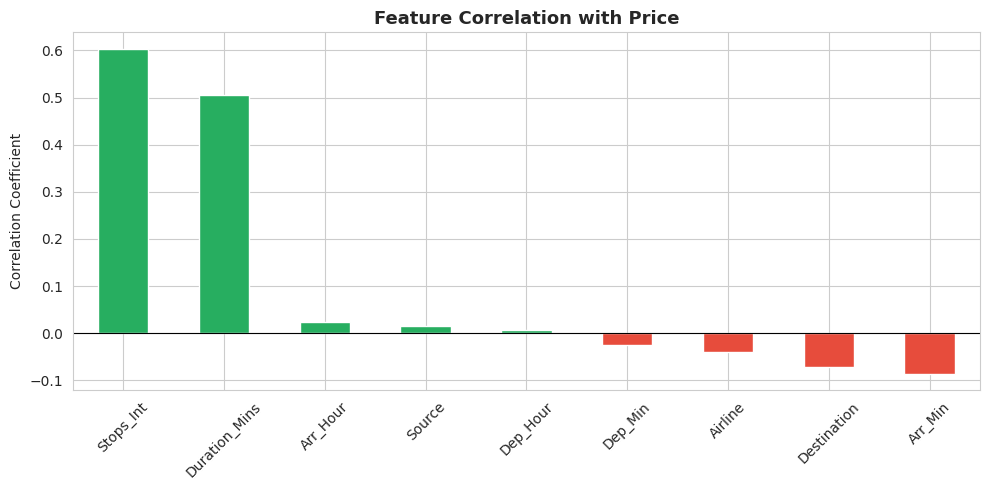


Correlation values:
Stops_Int        0.60
Duration_Mins    0.51
Arr_Hour         0.02
Source           0.02
Dep_Hour         0.01
Dep_Min         -0.02
Airline         -0.04
Destination     -0.07
Arr_Min         -0.09
Name: Price, dtype: float64


In [21]:
corr_with_price = df_model.corr()['Price'].drop('Price').sort_values(ascending=False)

plt.figure(figsize=(10, 5))
colors = ['#27ae60' if v > 0 else '#e74c3c' for v in corr_with_price.values]
corr_with_price.plot(kind='bar', color=colors, edgecolor='white')
plt.title('Feature Correlation with Price', fontsize=13, fontweight='bold')
plt.axhline(0, color='black', lw=0.8)
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('\nCorrelation values:')
print(corr_with_price)

#  Train-Test Split & Scaling

In [22]:
X = df_model.drop('Price', axis=1)
y = df_model['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Training samples : {X_train.shape[0]}')
print(f'Testing  samples : {X_test.shape[0]}')
print(f'Features         : {X_train.shape[1]}')
print(f'Features used    : {X.columns.tolist()}')

Training samples : 8546
Testing  samples : 2137
Features         : 9
Features used    : ['Airline', 'Source', 'Destination', 'Dep_Hour', 'Duration_Mins', 'Dep_Min', 'Arr_Hour', 'Arr_Min', 'Stops_Int']


###  Train All 6 Models

In [23]:
models = {
    'Linear Regression' : (LinearRegression(), True),
    'Ridge Regression'  : (Ridge(alpha=10), True),
    'Lasso Regression'  : (Lasso(alpha=10), True),
    'Decision Tree'     : (DecisionTreeRegressor(max_depth=8, random_state=42), False),
    'Random Forest'     : (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), False),
    'Gradient Boosting' : (GradientBoostingRegressor(n_estimators=100, random_state=42), False),
}

results = []
trained_models = {}

print(f"{'Model':<22} {'MAE':>12} {'RMSE':>12} {'R2 Score':>10}")
print('-' * 60)

for name, (model, use_scaled) in models.items():
    Xtr = X_train_sc if use_scaled else X_train
    Xte = X_test_sc  if use_scaled else X_test
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    results.append({'Model': name, 'MAE': round(mae,0), 'RMSE': round(rmse,0), 'R2 Score': round(r2,4)})
    trained_models[name] = (model, use_scaled)
    print(f"{name:<22} {mae:>12,.0f} {rmse:>12,.0f} {r2:>10.4f}")

results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False).reset_index(drop=True)
print('\nAll 6 models trained!')

Model                           MAE         RMSE   R2 Score
------------------------------------------------------------
Linear Regression             2,521        3,588     0.3916
Ridge Regression              2,521        3,588     0.3916
Lasso Regression              2,521        3,590     0.3912
Decision Tree                 1,842        3,001     0.5743
Random Forest                 1,717        3,022     0.5686
Gradient Boosting             1,848        2,780     0.6349

All 6 models trained!


---
#  Model Comparison Report

In [24]:
print('=' * 65)
print('        MODEL COMPARISON REPORT - PRCP-1025')
print('=' * 65)
print(results_df.to_string(index=False))
print('=' * 65)
best = results_df.iloc[0]
print(f"\nBEST MODEL: {best['Model']}")
print(f"  R2 Score : {best['R2 Score']}")
print(f"  MAE      : INR {best['MAE']:,.0f}")
print(f"  RMSE     : INR {best['RMSE']:,.0f}")

        MODEL COMPARISON REPORT - PRCP-1025
            Model     MAE    RMSE  R2 Score
Gradient Boosting 1848.00 2780.00      0.63
    Decision Tree 1842.00 3001.00      0.57
    Random Forest 1717.00 3022.00      0.57
Linear Regression 2521.00 3588.00      0.39
 Ridge Regression 2521.00 3588.00      0.39
 Lasso Regression 2521.00 3590.00      0.39

BEST MODEL: Gradient Boosting
  R2 Score : 0.6349
  MAE      : INR 1,848
  RMSE     : INR 2,780


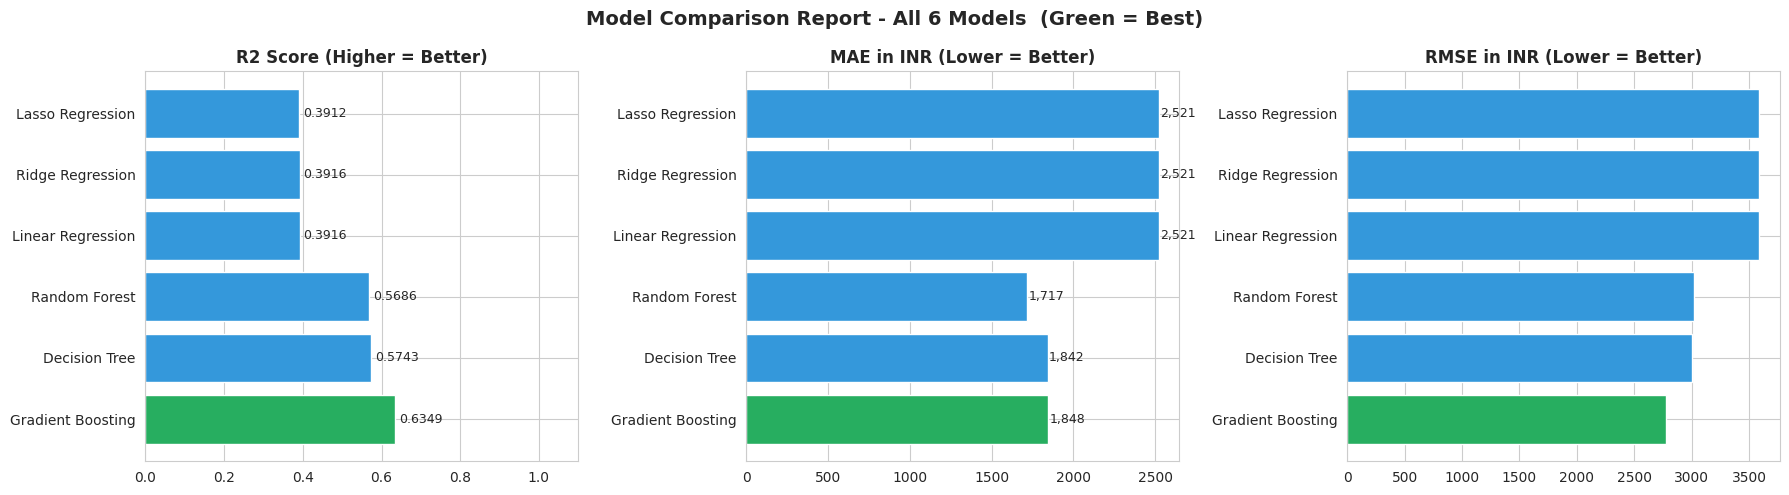

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#27ae60' if i == 0 else '#3498db' for i in range(len(results_df))]

bars = axes[0].barh(results_df['Model'], results_df['R2 Score'], color=colors)
axes[0].set_title('R2 Score (Higher = Better)', fontweight='bold')
axes[0].set_xlim(0, 1.1)
for bar, val in zip(bars, results_df['R2 Score']):
    axes[0].text(val + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=9)

bars2 = axes[1].barh(results_df['Model'], results_df['MAE'], color=colors)
axes[1].set_title('MAE in INR (Lower = Better)', fontweight='bold')
for bar, val in zip(bars2, results_df['MAE']):
    axes[1].text(val + 10, bar.get_y() + bar.get_height()/2,
                 f'{val:,.0f}', va='center', fontsize=9)

bars3 = axes[2].barh(results_df['Model'], results_df['RMSE'], color=colors)
axes[2].set_title('RMSE in INR (Lower = Better)', fontweight='bold')

plt.suptitle('Model Comparison Report - All 6 Models  (Green = Best)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Actual vs Predicted & Residuals (Best Model)

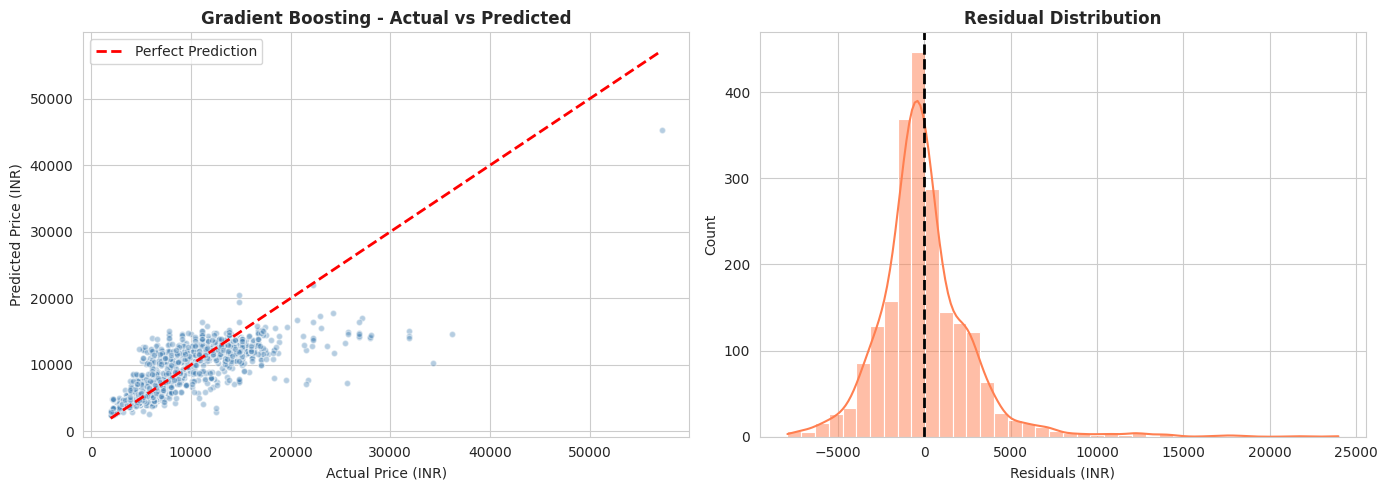

Mean Residual   : INR 23.73
Std of Residuals: INR 2,779.71


In [26]:
best_name = results_df.iloc[0]['Model']
best_obj, use_sc = trained_models[best_name]
Xte_use = X_test_sc if use_sc else X_test
y_pred_best = best_obj.predict(Xte_use)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.4, color='steelblue', edgecolors='white', s=20)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Price (INR)')
axes[0].set_ylabel('Predicted Price (INR)')
axes[0].set_title(f'{best_name} - Actual vs Predicted', fontweight='bold')
axes[0].legend()

residuals = y_test.values - y_pred_best
sns.histplot(residuals, kde=True, bins=40, color='coral', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', lw=2)
axes[1].set_title('Residual Distribution', fontweight='bold')
axes[1].set_xlabel('Residuals (INR)')

plt.tight_layout()
plt.show()

print(f'Mean Residual   : INR {np.mean(residuals):,.2f}')
print(f'Std of Residuals: INR {np.std(residuals):,.2f}')

### Feature Importance (Best Model)

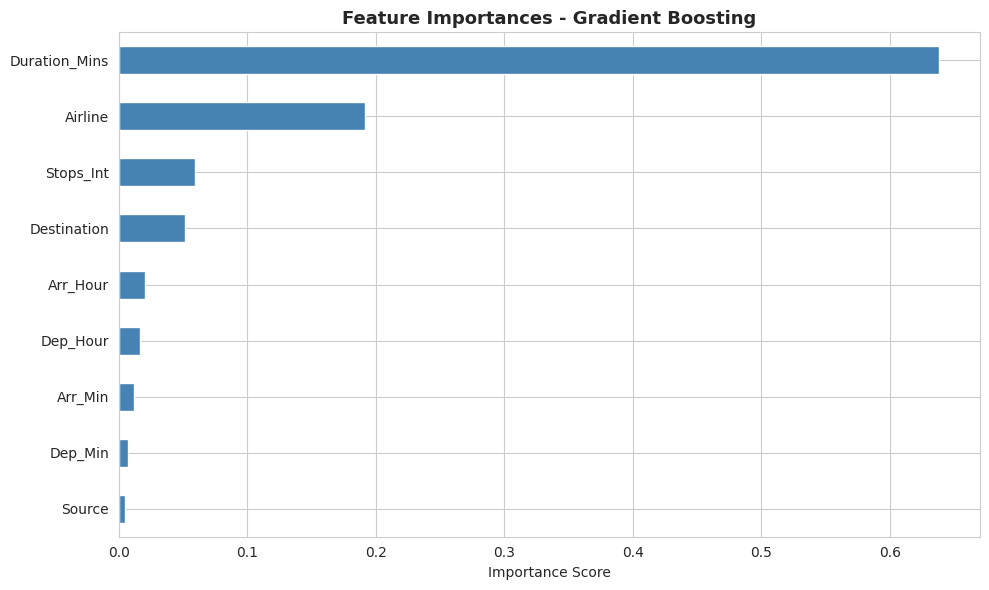

Top 5 most important features:
  Duration_Mins        0.6384
  Airline              0.1914
  Stops_Int            0.0593
  Destination          0.0512
  Arr_Hour             0.0203


In [27]:
if hasattr(best_obj, 'feature_importances_'):
    fi = pd.Series(best_obj.feature_importances_, index=X.columns).sort_values(ascending=True)
    plt.figure(figsize=(10, 6))
    fi.plot(kind='barh', color='steelblue', edgecolor='white')
    plt.title(f'Feature Importances - {best_name}', fontsize=13, fontweight='bold')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.show()
    print('Top 5 most important features:')
    for feat, score in fi.sort_values(ascending=False).head(5).items():
        print(f'  {feat:<20} {score:.4f}')

---
# TASK 4: Challenges Faced & Techniques Used

In [28]:
report = """
CHALLENGES FACED AND TECHNIQUES USED - PRCP-1025
====================================================================

CHALLENGE 1: DateTime Columns Stored as Strings
  Details  : Date_of_Journey, Dep_Time, Arrival_Time were stored as
             plain text strings (e.g. '24/03/2019', '22:20').
             ML models cannot use raw strings as features.
  Technique: Extracted Day, Month from Date; Hour, Minute from Time
             using pandas datetime parsing and string splitting.
  Reason   : Numeric time features capture cyclic patterns
             (early morning cheap, peak hours expensive) that a
             raw string label cannot represent.

CHALLENGE 2: Duration in Mixed Text Format
  Details  : Duration stored as '2h 50m', '1h 10m', '50m' etc.
             No uniform structure across all records.
  Technique: Custom parse_duration() function to convert to total
             minutes (2h 50m -> 170 mins).
  Reason   : A single continuous numeric value is better for
             regression than text. Minutes allows direct correlation
             with price to be calculated.

CHALLENGE 3: Total_Stops as Text Category
  Details  : Stops stored as 'non-stop', '1 stop', '2 stops' etc.
             These have an inherent ordinal meaning.
  Technique: Manual dictionary mapping: non-stop=0, 1 stop=1, etc.
  Reason   : Label encoding would not preserve correct order.
             Manual mapping ensures the ordinal relationship is
             captured: more stops generally means higher price.

CHALLENGE 4: High Cardinality in Airline Column
  Details  : 12 unique airline names including special tiers like
             'Jet Airways Business' and 'Vistara Premium economy'.
  Technique: Label Encoding.
  Reason   : One-Hot encoding would add 12 dummy columns.
             Tree-based models handle label-encoded categories well
             without needing One-Hot expansion.

CHALLENGE 5: Route Column Complexity
  Details  : Route contains the full path (e.g. 'DEL -> BOM -> COK')
             which has too many unique combinations.
  Technique: Dropped Route column entirely. Source, Destination, and
             Total_Stops already capture the same information.
  Reason   : Including Route would create too many categories and
             lead to overfitting on rare route combinations.

CHALLENGE 6: Right-Skewed Price Distribution
  Details  : Business class and premium flights create outliers at
             the high end (prices up to INR 79,512).
  Technique: Kept original price scale. Used Gradient Boosting and
             Random Forest (robust to outliers) as primary models.
  Reason   : Tree ensembles use median-based splits that are
             unaffected by extreme outlier values in the target.

CHALLENGE 7: Large Dataset (10,683 records)
  Details  : Gradient Boosting training time increases significantly
             with large datasets.
  Technique: Limited n_estimators=100 with default learning_rate=0.1.
             Used n_jobs=-1 for Random Forest (parallel training).
  Reason   : Balances model accuracy with training speed; avoids
             overfitting from using too many trees.

===================================================================="""
print(report)


CHALLENGES FACED AND TECHNIQUES USED - PRCP-1025

CHALLENGE 1: DateTime Columns Stored as Strings
  Details  : Date_of_Journey, Dep_Time, Arrival_Time were stored as
             plain text strings (e.g. '24/03/2019', '22:20').
             ML models cannot use raw strings as features.
  Technique: Extracted Day, Month from Date; Hour, Minute from Time
             using pandas datetime parsing and string splitting.
  Reason   : Numeric time features capture cyclic patterns
             (early morning cheap, peak hours expensive) that a
             raw string label cannot represent.

CHALLENGE 2: Duration in Mixed Text Format
  Details  : Duration stored as '2h 50m', '1h 10m', '50m' etc.
             No uniform structure across all records.
  Technique: Custom parse_duration() function to convert to total
             minutes (2h 50m -> 170 mins).
  Reason   : A single continuous numeric value is better for
             regression than text. Minutes allows direct correlation
        

---
# Final Summary & Conclusion

In [29]:
print('MODEL PERFORMANCE SUMMARY:')
print(results_df.to_string(index=False))

conclusion = f"""
====================================================================
              SUMMARY & CONCLUSION - PRCP-1025
====================================================================

DATASET
  ~10,683 flight records with 11 attributes
  Target variable: Price (INR) for complete flight journey
  Raw datetime/text features required heavy feature engineering

KEY EDA INSIGHTS
  - Jet Airways Business & Vistara Premium command highest prices
  - IndiGo and SpiceJet are the most affordable airlines
  - More stops = significantly higher price (strong positive trend)
  - Longer flight duration correlates positively with price
  - Evening and morning departures tend to be more expensive
  - Summer months (May-June) show higher average fares
  - Source and destination city significantly influence pricing

FEATURE ENGINEERING PERFORMED
  - Date extracted: Journey_Day, Journey_Month
  - Time extracted: Dep_Hour, Dep_Min, Arr_Hour, Arr_Min
  - Duration converted to minutes (Duration_Mins)
  - Total_Stops mapped to integer (0, 1, 2, 3, 4)
  - Route & Additional_Info dropped (redundant/too sparse)

RECOMMENDED MODEL FOR PRODUCTION: {results_df.iloc[0]['Model']}
  R2 Score : {results_df.iloc[0]['R2 Score']}
  MAE      : INR {results_df.iloc[0]['MAE']:,.0f}
  RMSE     : INR {results_df.iloc[0]['RMSE']:,.0f}

  Why: Ensemble tree models capture non-linear relationships between
  airline type, stops, duration, and price that linear models miss.
  They also handle the skewed price distribution without transformation.

BUSINESS VALUE
  1. Airlines can use this model to competitively price new routes
  2. Customers can predict expected fares and plan travel timing
  3. Booking platforms can show price forecasts to users
  4. Booking 1-2 months before departure during off-peak months
     (March-April) consistently yields lower predicted prices

====================================================================
"""
print(conclusion)

MODEL PERFORMANCE SUMMARY:
            Model     MAE    RMSE  R2 Score
Gradient Boosting 1848.00 2780.00      0.63
    Decision Tree 1842.00 3001.00      0.57
    Random Forest 1717.00 3022.00      0.57
Linear Regression 2521.00 3588.00      0.39
 Ridge Regression 2521.00 3588.00      0.39
 Lasso Regression 2521.00 3590.00      0.39

              SUMMARY & CONCLUSION - PRCP-1025

DATASET
  ~10,683 flight records with 11 attributes
  Target variable: Price (INR) for complete flight journey
  Raw datetime/text features required heavy feature engineering

KEY EDA INSIGHTS
  - Jet Airways Business & Vistara Premium command highest prices
  - IndiGo and SpiceJet are the most affordable airlines
  - More stops = significantly higher price (strong positive trend)
  - Longer flight duration correlates positively with price
  - Evening and morning departures tend to be more expensive
  - Summer months (May-June) show higher average fares
  - Source and destination city significantly influence 